## Representación en grafos: Grafo

- Se define el grafo sobre el que se aprenden los embeddings: **co-participación proveedor — proveedor**

- Se decide qué hacer con los hubs y se arma la co-participación **por año** para la predicción de enlaces

- **Spark:** atributos de los proveedores y co-participación por año (self-join de 2.9M participaciones)

- **Local:** scipy para componentes y hubs (el grafo cabe en 40 MB)

#### Enfoque

- **PQ2:** ¿los embeddings agrupan a los proveedores por región, por rubro o por rol en el mercado?

- **PQ3:** ¿qué pares de proveedores que aún no compiten juntos ocupan una posición parecida en la red?

### Constantes

- `RANGO_HUB`: percentiles de grado desde los que un proveedor se considera hub y se retira

- `TOP_HUBS` = 15: hubs que se listan

In [1]:
RANGO_HUB = [1.0, 0.999, 0.995, 0.99]
TOP_HUBS = 15

### Utilidades

In [2]:
NOTEBOOK = "a_grafo"
%run ../funciones.ipynb
%run funciones.ipynb

Note: you may need to restart the kernel to use updated packages.


In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

- `grafo_coparticipacion`: arista si dos proveedores participaron juntos 

- **≥ 2 procesos** de 2 a 30 participantes; peso = Σ 1/(n − 1)

- `participantes`, `procesos` y `hechos` de `data/final/`: región, rubro y año de cada participación

In [4]:
v_s = leer(artef_dir, "grafo_coparticipacion/vertices")
a_s = leer(artef_dir, "grafo_coparticipacion/aristas")
part = leer(final_dir, "participantes")
procesos = leer(final_dir, "procesos")
hechos = leer(final_dir, "hechos")
print(f"vértices: {v_s.count():,} | aristas: {a_s.count():,} | participaciones: {part.count():,}")

vértices: 60,213 | aristas: 1,639,945 | participaciones: 2,906,242


---
### **1. Atributos de los proveedores**

- **Región**: región (de la entidad) donde más procesos disputó

- **Familia UNSPSC** = la más frecuente entre los procesos adjudicados en que participó (4 dígitos)

- Son atributos **descriptivos** para interpretar los embeddings

In [5]:
fam_ocid = (hechos.where("familia IS NOT NULL AND familia <> 'SIN'")
            .groupBy("ocid", "familia").agg(F.sum("monto_asignado").alias("m"))
            .withColumn("r", F.row_number().over(Window.partitionBy("ocid").orderBy(F.desc_nulls_last("m"))))
            .where("r = 1").select("ocid", "familia"))
pp = part.select("ocid", "proveedor_key", "gano").join(F.broadcast(procesos.select("ocid", "region", "anio")), "ocid")

def moda(df, col):
    w = Window.partitionBy("proveedor_key").orderBy(F.desc("n"), col)
    return (df.where(F.col(col).isNotNull()).groupBy("proveedor_key", col).agg(F.count("*").alias("n"))
              .withColumn("r", F.row_number().over(w)).where("r = 1").select("proveedor_key", col))

act = pp.groupBy("proveedor_key").agg(F.count("*").alias("n_procesos"), F.sum("gano").alias("n_ganados"),
                                       F.countDistinct("region").alias("n_regiones"))
attr = (act.join(moda(pp, "region"), "proveedor_key", "left")
           .join(moda(pp.join(fam_ocid, "ocid"), "familia"), "proveedor_key", "left")
           .withColumn("segmento", F.substring("familia", 1, 2)))
attr_p = attr.join(v_s.select(F.substring("id", 3, 100).alias("proveedor_key")), "proveedor_key").toPandas()
pd.DataFrame([("proveedores del grafo", len(attr_p)),
              ("% con región", 100 * attr_p.region.notna().mean()),
              ("% con familia UNSPSC", 100 * attr_p.familia.notna().mean()),
              ("regiones distintas", attr_p.region.nunique()), ("familias distintas", attr_p.familia.nunique()),
              ("% en > 1 región", 100 * (attr_p.n_regiones > 1).mean()),
              ("% que nunca ganó", 100 * (attr_p.n_ganados == 0).mean())], columns=["medida", "valor"]).round(1)

,medida,valor
0,proveedores del grafo,60213.0
1,% con región,100.0
2,% con familia UNSPSC,96.5
3,regiones distintas,25.0
4,familias distintas,316.0
5,% en > 1 región,61.6
6,% que nunca ganó,54.9


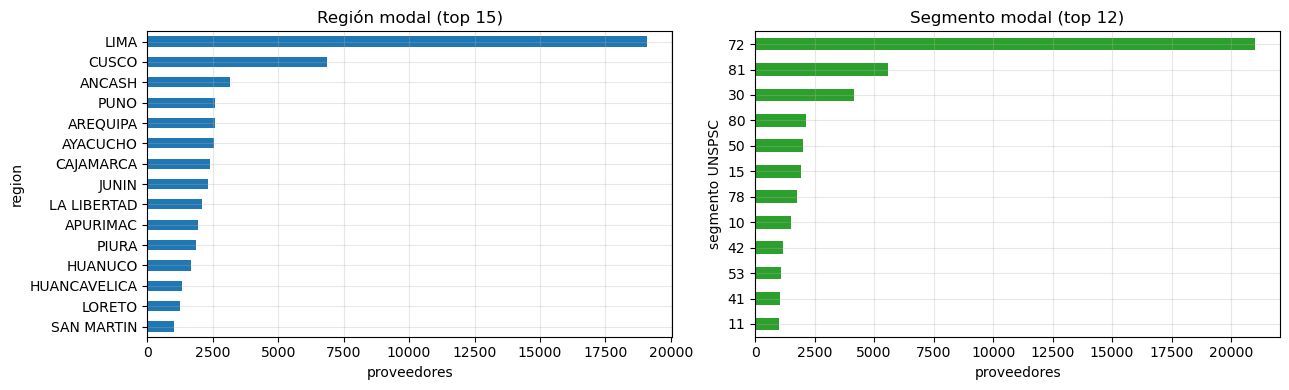

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
attr_p.region.value_counts().head(15)[::-1].plot.barh(ax=ax[0], color="tab:blue")
ax[0].set(xlabel="proveedores", title="Región modal (top 15)")
attr_p.segmento.dropna().value_counts().head(12)[::-1].plot.barh(ax=ax[1], color="tab:green")
ax[1].set(xlabel="proveedores", ylabel="segmento UNSPSC", title="Segmento modal (top 12)")
mostrar_fig("atributos")

- **Todos** tienen región y el **96.5%** tiene familia UNSPSC (25 regiones y 316 familias)

- **54.9% de los nodos nunca ganó:** el grafo de co-participación es sobre todo de **postores**, no de adjudicatarios

- Por eso solo una parte del grafo tiene tipología de la Parte II (que agrupa a ganadores con ≥ 3 procesos)

- **61.6% oferta en más de una región:** la región modal es una etiqueta gruesa, no una ubicación

- **Lima concentra ~19k proveedores (32%)**, seguida de Cusco (~7k); por rubro domina **obras (segmento 72, ~21k)**, luego consultoría (81) y materiales de construcción (30)

---
### **2. Estructura del grafo**

In [7]:
v, a = cargar_coparticipacion()
v = v.drop(columns="region").merge(attr_p.rename(columns={"proveedor_key": "clave"}), on="clave", how="left")
A = matriz_adyacencia(a.i.to_numpy(), a.j.to_numpy(), a.peso.to_numpy(), len(v))
v["grado"] = np.diff(A.indptr)
v["fuerza"] = np.asarray(A.sum(axis=1)).ravel()
n_comp, comp = connected_components(A, directed=False)
gig = np.bincount(comp).argmax()
estructura = pd.DataFrame([
    ("nodos", len(v)), ("aristas", len(a)), ("densidad", 2 * len(a) / (len(v) * (len(v) - 1))),
    ("grado p50", v.grado.median()), ("grado p99", v.grado.quantile(.99)), ("grado máx", v.grado.max()),
    ("componentes", n_comp), ("% nodos en la gigante", 100 * (comp == gig).mean()),
    ("% consorcios", 100 * v.es_consorcio.mean()),
    ("memoria CSR (MB)", (A.data.nbytes + A.indices.nbytes + A.indptr.nbytes) / 1e6)], columns=["medida", "valor"])
estructura.round(4)

,medida,valor
0,nodos,6.021300e+04
1,aristas,1.639945e+06
2,densidad,9.000000e-04
3,grado p50,1.700000e+01
4,grado p99,5.547600e+02
5,grado máx,1.205900e+04
6,componentes,7.610000e+02
7,% nodos en la gigante,9.628490e+01
8,% consorcios,7.274000e-01
9,memoria CSR (MB),3.959950e+01


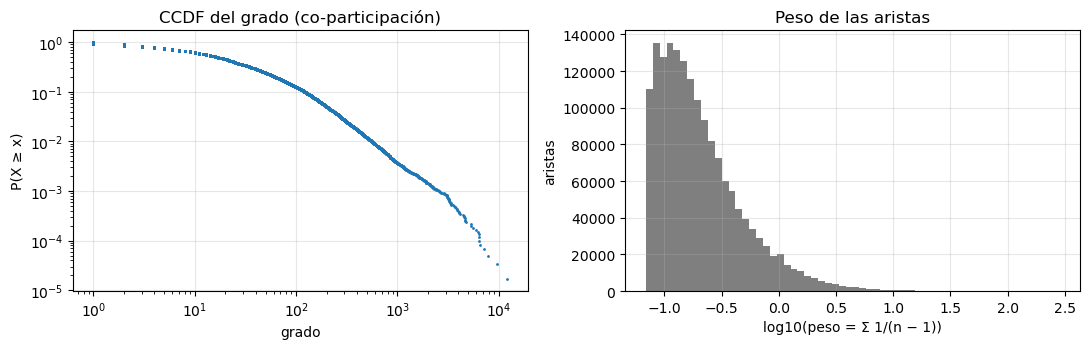

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.sort(v.grado.to_numpy())
ax[0].loglog(x, 1 - np.arange(len(x)) / len(x), ".", ms=2)
ax[0].set(xlabel="grado", ylabel="P(X ≥ x)", title="CCDF del grado (co-participación)")
ax[1].hist(np.log10(a.peso), bins=60, color="tab:gray")
ax[1].set(xlabel="log10(peso = Σ 1/(n − 1))", ylabel="aristas", title="Peso de las aristas")
mostrar_fig("estructura")

- **60,213 proveedores y 1.64M aristas** (densidad 0.09%): disperso, pero con grado mediano 17

- **Cola pesada:** grado p99 = 555 y máximo 12,059

- **761 componentes**, pero la gigante tiene el 96.3% de los nodos

---
### **3. Hubs**

- **Paseo aleatorio:** un caminante salta de proveedor en proveedor por las aristas, eligiendo el siguiente con más probabilidad cuanto mayor es el peso de la arista; Node2Vec aprende de miles de estos paseos (los proveedores que aparecen juntos en un paseo quedan cerca en el embedding)

- **Masa de visita:** fracción del tiempo que el paseo pasa en cada proveedor; es proporcional a su **fuerza** (Σ pesos de sus aristas)

$$\text{masa}(i) = \frac{\text{fuerza}(i)}{\sum_j \text{fuerza}(j)}$$

- Si pocos hubs concentran la masa, los paseos pasan por ellos todo el tiempo

- Para cada umbral se retiran los nodos con grado sobre ese percentil y se mide qué se pierde (**% de aristas perdidas**) y qué se gana (**masa del top 1% restante**: % de las visitas que se lleva el 1% más fuerte del grafo que queda; más bajo = paseos más repartidos)

In [9]:
masa = v.fuerza / v.fuerza.sum()
umbral_hub = []
for pct in RANGO_HUB:
    corte = v.grado.quantile(pct) if pct < 1 else np.inf
    queda = (v.grado <= corte).to_numpy()
    Aq = A[queda][:, queda]
    gq = componente_gigante(Aq)
    fz = np.asarray(Aq.sum(axis=1)).ravel()
    top = np.sort(fz)[::-1][: max(1, int(.01 * queda.sum()))].sum() / fz.sum()
    umbral_hub.append({"percentil": pct, "corte_grado": corte, "hubs_retirados": int((~queda).sum()),
                       "% aristas perdidas": 100 * (1 - Aq.nnz / A.nnz),
                       "% masa de visita retirada": 100 * masa[~queda].sum(),
                       "% nodos en la gigante": 100 * len(gq) / queda.sum(),
                       "masa del top 1% restante": 100 * top})
umbral_hub = pd.DataFrame(umbral_hub).round(2).assign(percentil=RANGO_HUB)
umbral_hub

,percentil,corte_grado,hubs_retirados,% aristas perdidas,% masa de visita retirada,% nodos en la gigante,masa del top 1% restante
0,1.000,inf,0,0.00,0.00,96.28,35.48
1,0.999,2545.52,61,15.53,11.42,94.67,28.74
2,0.995,837.88,302,33.43,24.31,92.63,23.27
3,0.990,554.76,603,43.82,32.23,91.65,20.64


#### a. ¿Quiénes son los hubs?

In [10]:
v["tasa_exito"] = v.n_ganados / v.n_procesos
cols = ["nombre", "grado", "n_procesos", "n_ganados", "tasa_exito", "region", "familia"]
hubs = v.nlargest(TOP_HUBS, "grado")[cols].round(3)
hubs

,nombre,grado,n_procesos,n_ganados,tasa_exito,region,familia
56759,TVT QONTRATISTAS E.I.R.L.,12059,11646,24,0.002,LIMA,7212
45349,INVERSIONES GENERALES LAURA ROCA S.A.C.,9522,8406,2,0.000,LIMA,7212
27375,CRISAMYR SOCIEDAD ANONIMA CERRADA,7854,8932,0,0.000,LIMA,7214
58370,CONSTRUCAPRIGLE E.I.R.L.,7168,6107,12,0.002,LIMA,7212
27190,CORPORACION GRUPO IBIZA S.A.C.,6523,8481,2,0.000,ANCASH,7214
56186,ALLENDE CONTRATISTAS E.I.R.L.,6433,4931,4,0.001,LIMA,7212
58882,OCAMPER S.A.C.,6431,5184,5,0.001,LIMA,7214
53262,INVERSIONES Y EDIFICACIONES JYR S.A.C.,6380,5521,8,0.001,LIMA,2510
50213,CONSTRUCTORA ART PERU E.I.R.L.,6294,4729,0,0.000,LIMA,7214
40981,TECNICAS DE INGENIERIA Y CONTRATOS S.A.C. - TEINGECON S.A.C.,6012,5630,5,0.001,ANCASH,7214


In [11]:
es_hub = v.grado > v.grado.quantile(.999)
pd.DataFrame({"hubs (top 0.1%)": v[es_hub][["n_procesos", "tasa_exito", "n_regiones"]].median(),
              "resto": v[~es_hub][["n_procesos", "tasa_exito", "n_regiones"]].median(),
              }).T.assign(**{"% obras (familias 72xx)": [100 * v[m].familia.fillna("").str.startswith("72").mean() for m in (es_hub, ~es_hub)]}).round(3)

,n_procesos,tasa_exito,n_regiones,% obras (familias 72xx)
hubs (top 0.1%),3887.0,0.001,25.0,70.492
resto,10.0,0.000,2.0,34.852


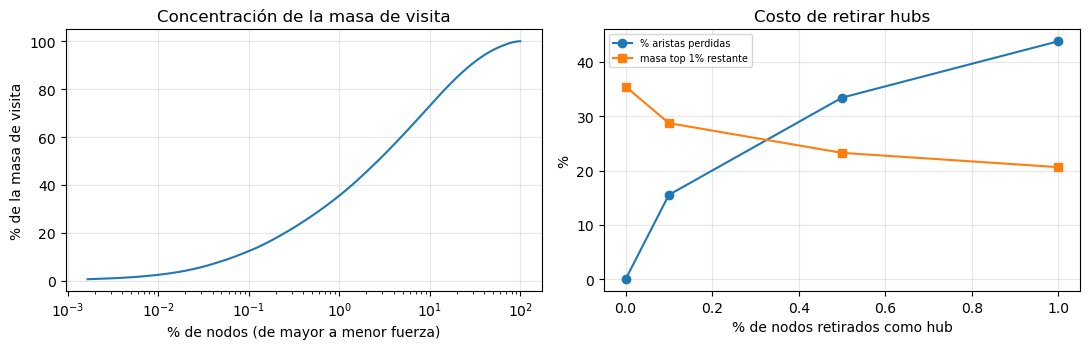

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
orden = np.sort(masa.to_numpy())[::-1]
ax[0].plot(100 * np.arange(1, len(orden) + 1) / len(orden), 100 * np.cumsum(orden))
ax[0].set(xscale="log", xlabel="% de nodos (de mayor a menor fuerza)", ylabel="% de la masa de visita",
          title="Concentración de la masa de visita")
ax[1].plot(100 * (1 - umbral_hub.percentil), umbral_hub["% aristas perdidas"], "o-", label="% aristas perdidas")
ax[1].plot(100 * (1 - umbral_hub.percentil), umbral_hub["masa del top 1% restante"], "s-", label="masa top 1% restante")
ax[1].set(xlabel="% de nodos retirados como hub", ylabel="%", title="Costo de retirar hubs"); ax[1].legend(fontsize=7)
mostrar_fig("hubs")

- **Los hubs no son grandes proveedores: son postores masivos.** TVT Qontratistas en 11,646 procesos y ganó 24

- Casi todos son de **obras** (familias 7212, 7214) en Lima y Áncash: ofertan a todo lo que se convoca en su rubro

- Sus aristas miden **volumen de oferta, no afinidad**: coincidir con un postor masivo en 2 procesos no dice nada

- **Masa de visita:** sin retirar a nadie, el 1% de nodos con más fuerza se lleva el **35.5%** de los pasos de un paseo

- **Retirar el top 0.1% (61 nodos)** quita 11.4% de la masa y 15.5% de las aristas

- Pasar a 0.5% o 1% retira 300-600 nodos y un tercio o más de las aristas

- Se fija `PCT_HUB = 0.999`: solo los postores masivos extremos

In [13]:
PCT_HUB = 0.999

#### a. Subgrafo final

Se quitan los hubs según `PCT_HUB` y se conserva la componente gigante

In [14]:
corte = v.grado.quantile(PCT_HUB) if PCT_HUB < 1 else np.inf
queda = np.flatnonzero((v.grado <= corte).to_numpy())
g = queda[componente_gigante(A[queda][:, queda])]
nodos = v.iloc[g].reset_index(drop=True).rename(columns={"idx": "idx_artefacto"})
nodos["idx"] = np.arange(len(nodos))
mapa = np.full(len(v), -1); mapa[g] = nodos.idx
ar = a.assign(i=mapa[a.i], j=mapa[a.j]).query("i >= 0 and j >= 0")[["i", "j", "peso", "n_coparticipa"]]
print(f"subgrafo: {len(nodos):,} nodos ({100 * len(nodos) / len(v):.1f}%) | {len(ar):,} aristas ({100 * len(ar) / len(a):.1f}%)")

subgrafo: 56,948 nodos (94.6%) | 1,382,617 aristas (84.3%)


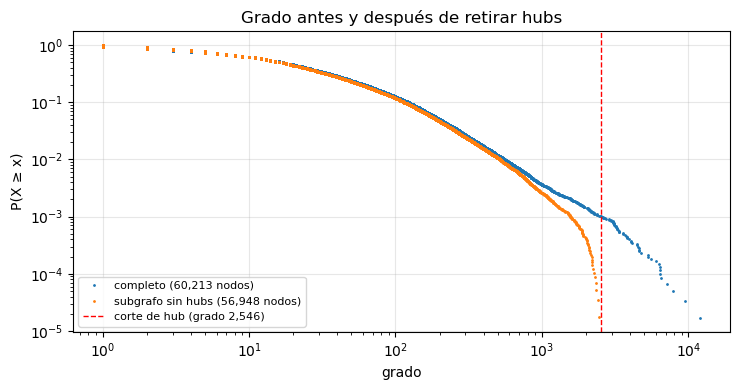

In [15]:
g_sub = np.bincount(np.r_[ar.i, ar.j], minlength=len(nodos))
fig, ax = plt.subplots(figsize=(7.5, 4))
for x_, lbl in ((v.grado.to_numpy(), f"completo ({len(v):,} nodos)"), (g_sub, f"subgrafo sin hubs ({len(nodos):,} nodos)")):
    x_ = np.sort(x_[x_ > 0])
    ax.loglog(x_, 1 - np.arange(len(x_)) / len(x_), ".", ms=2, label=lbl)
ax.axvline(corte, ls="--", c="red", lw=1, label=f"corte de hub (grado {corte:,.0f})")
ax.set(xlabel="grado", ylabel="P(X ≥ x)", title="Grado antes y después de retirar hubs"); ax.legend(fontsize=8)
mostrar_fig("subgrafo")

- **El corte solo recorta la cola:** hasta grado ~1,000 las dos distribuciones coinciden

- Subgrafo conserva el **94.6%** de los nodos y el **84.3%** de las aristas

---
### **4. Co-participación por año**

- **Para predecir enlaces sin fuga** hace falta saber **cuándo** aparece cada arista

- Procesos de 2 a `MAX_PART` participantes, `repartition(ocid)` + `cache` antes del self-join

- Una arista del año = par que coincidió en **≥ `MIN_COMP` procesos ese año**

In [16]:
SHUFFLE = int(spark.conf.get("spark.sql.shuffle.partitions"))
p_anio = part.select("ocid", "proveedor_key").join(F.broadcast(procesos.select("ocid", "anio")), "ocid")
n_part = p_anio.groupBy("ocid").agg(F.count("*").alias("n"))
p_n = p_anio.join(n_part.where(f"n BETWEEN 2 AND {MAX_PART}"), "ocid").repartition(SHUFFLE, "ocid").cache()
pares_anio = (p_n.alias("a").join(p_n.alias("b"), (F.col("a.ocid") == F.col("b.ocid")) &
                                  (F.col("a.proveedor_key") < F.col("b.proveedor_key")))
              .select(F.col("a.proveedor_key").alias("src"), F.col("b.proveedor_key").alias("dst"), F.col("a.anio").alias("anio"),
                      F.col("a.n").alias("n"))
              .groupBy("src", "dst", "anio").agg(F.count("*").alias("n_coparticipa"), F.sum(1.0 / (F.col("n") - 1)).alias("peso"))
              .where(f"n_coparticipa >= {MIN_COMP}"))
aristas_anio = pares_anio.toPandas()
p_n.unpersist()
pos = pd.Series(nodos.idx.to_numpy(), index=nodos.clave)
aristas_anio = aristas_anio.assign(i=aristas_anio.src.map(pos), j=aristas_anio.dst.map(pos)).dropna(subset=["i", "j"])
aristas_anio = aristas_anio.astype({"i": int, "j": int})[["i", "j", "anio", "n_coparticipa", "peso"]]
extremos = pd.concat([aristas_anio[["anio", "i"]], aristas_anio[["anio", "j"]].rename(columns={"j": "i"})])
por_anio = (aristas_anio.groupby("anio").size().rename("aristas").to_frame()
            .join(extremos.groupby("anio").i.nunique().rename("nodos_activos")).reset_index())
por_anio

,anio,aristas,nodos_activos
0,2023,482854,30632
1,2024,490070,30973
2,2025,507875,31667


Cada año tiene **~480-510k aristas** entre 31k proveedores activos (los que co-participaron ≥ 2 veces ese año)

In [17]:
llave = lambda d: set(zip(d.i, d.j))
e = {y: llave(aristas_anio[aristas_anio.anio == y]) for y in anios}
nuevos = pd.DataFrame([
    ("2024 nuevas respecto de 2023", len(e[2024] - e[2023]), 100 * len(e[2024] - e[2023]) / len(e[2024])),
    ("2025 nuevas respecto de 2023-2024", len(e[2025] - e[2023] - e[2024]), 100 * len(e[2025] - e[2023] - e[2024]) / len(e[2025])),
    ("se repiten en los tres años", len(e[2023] & e[2024] & e[2025]), np.nan)], columns=["medida", "pares", "% del año"]).round(1)
nuevos

,medida,pares,% del año
0,2024 nuevas respecto de 2023,384137,78.4
1,2025 nuevas respecto de 2023-2024,372671,73.4
2,se repiten en los tres años,49048,NaN


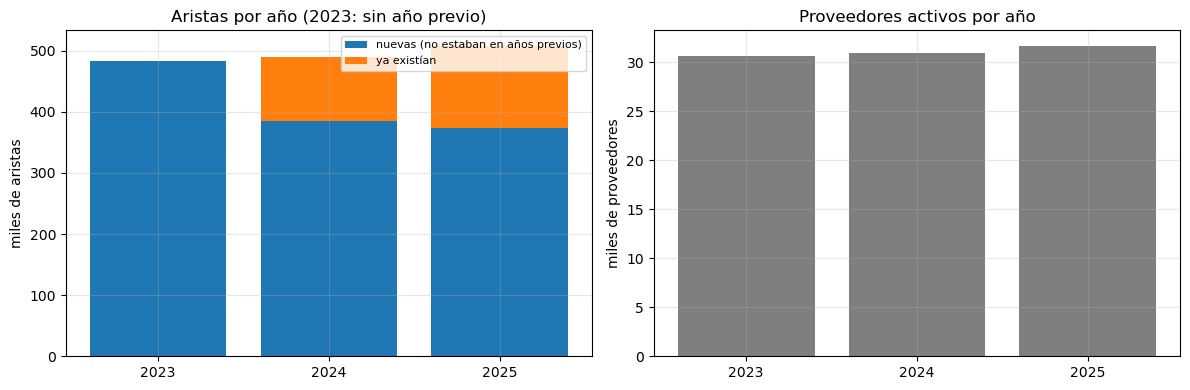

In [18]:
ya = {2023: 0, 2024: len(e[2024] & e[2023]), 2025: len(e[2025] & (e[2023] | e[2024]))}
nuevas = {y: len(e[y]) - ya[y] for y in anios}
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(anios, [nuevas[y] / 1e3 for y in anios], label="nuevas (no estaban en años previos)")
ax[0].bar(anios, [ya[y] / 1e3 for y in anios], bottom=[nuevas[y] / 1e3 for y in anios], label="ya existían")
ax[0].set(xticks=anios, ylabel="miles de aristas", title="Aristas por año (2023: sin año previo)"); ax[0].legend(fontsize=8)
ax[1].bar(por_anio["anio"], por_anio["nodos_activos"] / 1e3, color="tab:gray")
ax[1].set(xticks=anios, ylabel="miles de proveedores", title="Proveedores activos por año")
mostrar_fig("por_anio")

- **El 78% de las aristas de 2024 y el 73% de las de 2025 son nuevas:** co-participación se renueva mucho cada año

- Solo **49k pares** compiten juntos en los tres años: el núcleo estable de competidores recurrentes

- Hay **~380k pares nuevos por año** para evaluar: predecir quién empezará a competir con quién es una tarea **difícil**

- Cada año tiene 480-510k aristas y 31k proveedores activos, estables; lo que cambia es **quién** compite con quién

---
### **5. Exportación a `temp/datos/`**

- `nodos.parquet`: idx, clave, nombre, consorcio, grado, fuerza, región, familia, segmento y actividad

- `aristas.parquet`: subgrafo final (i < j) con `peso` y `n_coparticipa`

- `aristas_anio.parquet`: co-participación por año entre nodos del subgrafo

In [19]:
nodos[["idx", "clave", "nombre", "es_consorcio", "grado", "fuerza", "region", "familia", "segmento", "n_procesos",
       "n_ganados", "n_regiones"]].to_parquet(datos_dir / "nodos.parquet", index=False)
ar.to_parquet(datos_dir / "aristas.parquet", index=False)
aristas_anio.to_parquet(datos_dir / "aristas_anio.parquet", index=False)
config = leer_config()
config.update({"pct_hub": PCT_HUB, "n_nodos": len(nodos), "n_aristas": len(ar)})
guardar_config(config)

#### a. Verificación

Índices contiguos, aristas dentro del subgrafo y un solo componente

In [20]:
nd, ad = pd.read_parquet(datos_dir / "nodos.parquet"), pd.read_parquet(datos_dir / "aristas.parquet")
assert (nd.idx.to_numpy() == np.arange(len(nd))).all()
assert ad[["i", "j"]].max().max() < len(nd) and (ad.i < ad.j).all()
assert connected_components(matriz_adyacencia(ad.i, ad.j, ad.peso, len(nd)), directed=False)[0] == 1
print(f"OK: {len(nd):,} nodos, {len(ad):,} aristas, {len(aristas_anio):,} aristas por año")

OK: 56,948 nodos, 1,382,617 aristas, 1,480,799 aristas por año


---
### **6. Escritura de resultados**

In [21]:
escritos = guardar_tablas({"estructura": estructura.astype({"valor": float}), "umbral_hub": umbral_hub,
                           "hubs": hubs.fillna("sin dato"), "por_anio": por_anio, "nuevos_por_anio": nuevos.fillna(0)})

Escrito en 06_Representacion/temp/a_grafo/: estructura, umbral_hub, hubs, por_anio, nuevos_por_anio


#### a. Verificación

In [22]:
verificar_salidas(escritos)

OK: 5 tablas (parquet + json) | 5 figuras: atributos, estructura, hubs, por_anio, subgrafo


---
### **7. Cerrar sesión**

In [23]:
spark.stop()